# BC01 — Partie 3 | Qualité des données et agrégations SQL

Épreuve d’entraînement CycleNova. Remplissez **vos propres réponses** dans les cellules. Les trois fichiers sont disponibles en local. Aucune solution n’est fournie ici.

## Étape 0 — Charger les données (exécutable sans modification)

In [15]:
from pathlib import Path
import pandas as pd
import numpy as np

def trouver_donnees():
    bases = [Path.cwd(), Path.cwd().parent, Path('/content'), Path('/content/CycleNova_Entrainement_RNCP38616')]
    for base in bases:
        for d in (base / 'DONNEES', base / 'CycleNova_Entrainement_RNCP38616' / 'DONNEES'):
            if (d / 'ventes.csv').is_file() and (d / 'produits.csv').is_file() and (d / 'prix_concurrents.csv').is_file():
                return d
    archive = Path('/content/CycleNova_Entrainement_RNCP38616.zip')
    if archive.exists():
        import zipfile
        with zipfile.ZipFile(archive) as z:
            z.extractall('/content')
        return trouver_donnees()
    raise FileNotFoundError('Dossier DONNEES absent. Consultez LISEZMOI.md et conservez la structure des dossiers.')

DATA = trouver_donnees()
produits = pd.read_csv(DATA / 'produits.csv')
ventes = pd.read_csv(DATA / 'ventes.csv')
prix_concurrents = pd.read_csv(DATA / 'prix_concurrents.csv')
print(f'Données chargées : produits={len(produits)}, ventes={len(ventes)}, prix_concurrents={len(prix_concurrents)}')

Données chargées : produits=65, ventes=3005, prix_concurrents=2818


## Étape 1 — Comprendre la source

1. Quelle est la granularité de chaque table ? Quelles sont les clés attendues ?
2. Quels champs contiennent des valeurs personnelles ? Justifiez votre réponse.
3. Quels problèmes peuvent apparaître lors de la jointure des historiques de prix ?

In [16]:
# VOTRE REPONSE ET VOS CONTROLES :
# Granularité et unicité des clés attendues
print("PRODUITS")
print("  lignes :", len(produits))
print("  id_produit distincts :", produits["id_produit"].nunique())
print("  lignes entièrement dupliquées :", produits.duplicated().sum())

print("\nVENTES")
print("  lignes :", len(ventes))
print("  id_vente distincts :", ventes["id_vente"].nunique())
print("  lignes entièrement dupliquées :", ventes.duplicated().sum())

print("\nPRIX_CONCURRENTS")
cle_prix = ["id_produit", "concurrent", "date_releve"]
print("  lignes :", len(prix_concurrents))
print("  combinaisons (produit, concurrent, date) distinctes :",
      len(prix_concurrents.drop_duplicates(subset=cle_prix)))
print("  concurrents :", prix_concurrents["concurrent"].unique())
print("  période des relevés :", prix_concurrents["date_releve"].min(), "→", prix_concurrents["date_releve"].max())
print("  relevés par (produit, concurrent) :")
print(prix_concurrents.groupby(["id_produit", "concurrent"]).size().describe())

# Démonstration du risque de duplication par jointure directe sur l'historique des prix
jointure_naive = ventes.merge(prix_concurrents, on="id_produit", how="left")
print("\nJOINTURE NAÏVE ventes x prix_concurrents")
print("  lignes de ventes avant :", len(ventes))
print("  lignes après jointure  :", len(jointure_naive))
print("  facteur de multiplication ≈", round(len(jointure_naive) / len(ventes), 1))


PRODUITS
  lignes : 65
  id_produit distincts : 64
  lignes entièrement dupliquées : 1

VENTES
  lignes : 3005
  id_vente distincts : 3000
  lignes entièrement dupliquées : 5

PRIX_CONCURRENTS
  lignes : 2818
  combinaisons (produit, concurrent, date) distinctes : 2816
  concurrents : <ArrowStringArray>
['Concurrent A', 'Concurrent B']
Length: 2, dtype: str
  période des relevés : 2025-01-01 → 2026-10-01
  relevés par (produit, concurrent) :
count    128.000000
mean      22.015625
std        0.124507
min       22.000000
25%       22.000000
50%       22.000000
75%       22.000000
max       23.000000
dtype: float64

JOINTURE NAÏVE ventes x prix_concurrents
  lignes de ventes avant : 3005
  lignes après jointure  : 131480
  facteur de multiplication ≈ 43.8


### Réponses — Étape 1

**1. Granularité et clés attendues**

| Table | Une ligne = | Clé attendue | Constat |
|---|---|---|---|
| `produits` | un produit du catalogue | `id_produit` | 65 lignes pour 64 identifiants distincts : `P0010` apparaît deux fois (ligne strictement identique). |
| `ventes` | une ligne de vente d'un produit (une commande d'un produit en une certaine quantité) | `id_vente` | 3 005 lignes pour 3 000 identifiants distincts : 5 ventes sont dupliquées à l'identique (copie en fin de fichier). |
| `prix_concurrents` | un relevé de prix d'un produit chez un concurrent à une date | (`id_produit`, `concurrent`, `date_releve`) | 2 818 lignes pour 2 816 combinaisons distinctes : 2 relevés en double. 2 concurrents (A et B), un relevé mensuel le 1er du mois de janvier 2025 à octobre 2026, soit 22 relevés par couple (produit, concurrent). |

Relations : `ventes.id_produit` → `produits.id_produit` (plusieurs ventes pour un produit) et `prix_concurrents.id_produit` → `produits.id_produit` (plusieurs relevés pour un produit). Les doublons constatés violent la granularité attendue : ils devront être supprimés avant toute jointure ou agrégation, sinon ventes et chiffre d'affaires seraient comptés deux fois.

**2. Données personnelles**

Aucune colonne n'identifie directement une personne : pas de nom, d'e-mail, d'adresse, de téléphone ni même d'identifiant client. `id_vente` identifie une transaction, pas un individu ; `produits` et `prix_concurrents` ne décrivent que des produits et des prix de marché.
Points de vigilance cependant :
- dans le système réel, une vente est rattachée à un client : `id_vente` serait alors une **donnée pseudonymisée**, ré-identifiable par jointure avec la base clients, donc toujours soumise au RGPD ;
- le croisement `date_commande` + `produit` + `canal` + `retour` décrit le comportement d'achat d'une personne et pourrait contribuer à une ré-identification indirecte si on le recoupait avec d'autres sources ;
- `motif_retour` est ici une liste fermée (Taille, Défectueux, Changement avis), mais un champ libre pourrait contenir des informations personnelles (taille, santé, commentaire nominatif).
Conclusion : le jeu fourni est synthétique et ne contient pas de données personnelles directes, mais la table `ventes` est celle à protéger en priorité dans un contexte réel (minimisation, accès restreints, pseudonymisation).

**3. Problèmes lors de la jointure des historiques de prix**

- **Multiplication des lignes** : chaque produit a environ 44 relevés (2 concurrents × 22 mois). Une jointure directe sur `id_produit` duplique donc chaque vente environ 44 fois (voir le contrôle ci-dessus) : tout `SUM` du chiffre d'affaires ou `COUNT` des ventes serait massivement surévalué.
- **Doublons de relevés** : les 2 relevés en double ajoutent encore des lignes parasites s'ils ne sont pas retirés avant.
- **Choix du relevé pertinent** : pour comparer des prix, il faut **un seul relevé par (produit, concurrent)** — le plus récent pour une comparaison des prix courants, ou le dernier relevé **antérieur ou égal à la date de vente** pour une analyse au moment de l'achat. Utiliser un relevé postérieur à la vente introduit une incohérence temporelle (et une fuite d'information en machine learning).
- **Clés absentes ou inconnues** : une vente dont l'`id_produit` est manquant ou absent du catalogue ne trouvera pas de prix concurrent (valeurs NULL en LEFT JOIN, ligne perdue en INNER JOIN).
- **Granularités différentes** : le prix concurrent est mensuel alors que la vente est datée au jour ; il faut expliciter la règle d'alignement des dates.

## Étape 2 — Initialiser une base SQLite locale

Les requêtes SQL suivantes doivent être rédigées en SQLite depuis le notebook. Pour la copie des trois tables dans BigQuery, voir **BC01 Partie 2** du sujet.

In [17]:
import sqlite3
connexion = sqlite3.connect(":memory:")
produits.to_sql("produits", connexion, index=False, if_exists="replace")
ventes.to_sql("ventes", connexion, index=False, if_exists="replace")
prix_concurrents.to_sql("prix_concurrents", connexion, index=False, if_exists="replace")
print(pd.read_sql_query("SELECT COUNT(*) AS n FROM ventes", connexion))

      n
0  3005


## Étape 3 — Contrôle qualité en SQL

Écrivez des requêtes pour :

1. Compter les lignes et les identifiants distincts de chaque table.
2. Repérer les identifiants de vente en doublon et les produits dupliqués.
3. Repérer les clés produit manquantes et celles absentes de la table `produits`.
4. Repérer quantités, prix, taux de remise et étiquettes de retour invalides.
5. Commenter l’impact de ces erreurs sur les indicateurs.

In [18]:
def sql(requete):
    """Exécute une requête SQL sur la base SQLite et renvoie un DataFrame."""
    return pd.read_sql_query(requete, connexion)

In [19]:
display(sql("""
SELECT 'produits' AS table_name, COUNT(*) AS n_lignes, COUNT(DISTINCT id_produit) AS n_cles_distinctes FROM produits
UNION ALL
SELECT 'ventes', COUNT(*), COUNT(DISTINCT id_vente) FROM ventes
UNION ALL
SELECT 'prix_concurrents', COUNT(*),
       (SELECT COUNT(*) FROM (SELECT DISTINCT id_produit, concurrent, date_releve FROM prix_concurrents))
FROM prix_concurrents
"""))

,table_name,n_lignes,n_cles_distinctes
0,produits,65,64
1,ventes,3005,3000
2,prix_concurrents,2818,2816


In [20]:
# Identifiants de vente présents plusieurs fois
display(sql("""
SELECT id_vente, COUNT(*) AS nb_occurrences
FROM ventes
GROUP BY id_vente
HAVING COUNT(*) > 1
ORDER BY id_vente
"""))

# Produits présents plusieurs fois dans le catalogue
display(sql("""
SELECT id_produit, COUNT(*) AS nb_occurrences
FROM produits
GROUP BY id_produit
HAVING COUNT(*) > 1
"""))

,id_vente,nb_occurrences
0,V000101,2
1,V000332,2
2,V001422,2
3,V002101,2
4,V002458,2


,id_produit,nb_occurrences
0,P0010,2


In [21]:
display(sql("""
SELECT
  SUM(CASE WHEN v.id_produit IS NULL THEN 1 ELSE 0 END) AS id_produit_manquant,
  SUM(CASE WHEN v.id_produit IS NOT NULL AND p.id_produit IS NULL THEN 1 ELSE 0 END) AS id_produit_inconnu
FROM ventes v
LEFT JOIN (SELECT DISTINCT id_produit FROM produits) p
  ON v.id_produit = p.id_produit
"""))

# Quels identifiants inconnus ?
display(sql("""
SELECT v.id_produit, COUNT(*) AS nb_ventes
FROM ventes v
LEFT JOIN (SELECT DISTINCT id_produit FROM produits) p ON v.id_produit = p.id_produit
WHERE v.id_produit IS NOT NULL AND p.id_produit IS NULL
GROUP BY v.id_produit
"""))

,id_produit_manquant,id_produit_inconnu
0,11,8


,id_produit,nb_ventes
0,P9999,8


In [22]:
display(sql("""
SELECT
  SUM(CASE WHEN quantite IS NULL OR quantite <= 0 THEN 1 ELSE 0 END)            AS quantite_invalide,
  SUM(CASE WHEN prix_unitaire IS NULL THEN 1 ELSE 0 END)                         AS prix_manquant,
  SUM(CASE WHEN prix_unitaire <= 0 THEN 1 ELSE 0 END)                            AS prix_negatif_ou_nul,
  SUM(CASE WHEN taux_remise IS NULL OR taux_remise < 0 OR taux_remise > 1 THEN 1 ELSE 0 END) AS remise_invalide,
  SUM(CASE WHEN retour IS NULL THEN 1 ELSE 0 END)                                AS retour_manquant,
  SUM(CASE WHEN retour NOT IN (0, 1) THEN 1 ELSE 0 END)                          AS retour_invalide,
  SUM(CASE WHEN canal IS NULL THEN 1 ELSE 0 END)                                 AS canal_manquant
FROM ventes
"""))

# Détail des valeurs observées pour les colonnes à modalités
display(sql("SELECT taux_remise, COUNT(*) AS n FROM ventes GROUP BY taux_remise ORDER BY taux_remise"))
display(sql("SELECT retour, COUNT(*) AS n FROM ventes GROUP BY retour ORDER BY retour"))

,quantite_invalide,prix_manquant,prix_negatif_ou_nul,remise_invalide,retour_manquant,retour_invalide,canal_manquant
0,7,11,5,8,5,4,8


,taux_remise,n
0,-0.20,4
1,0.00,2068
2,0.10,352
3,0.15,291
4,0.20,191
5,0.25,95
6,1.50,4


,retour,n
0,NaN,5
1,0.0,2494
2,1.0,502
3,2.0,4


## Étape 4 — Construire une source propre

Définissez explicitement vos règles d’exclusion ou de correction. Évitez toute duplication par jointure. Construisez une table temporaire `ventes_valides` contenant le montant par ligne `quantite * prix_unitaire * (1 - taux_remise)` et la catégorie du produit.

### Règles de nettoyage retenues

| Problème | Règle | Justification |
|---|---|---|
| `id_vente` en double | **Dédoublonnage** : une seule ligne conservée par `id_vente` | Les doublons sont des copies strictement identiques : les garder compterait deux fois la vente. |
| `P0010` dupliqué dans `produits` | Jointure sur une version **dédoublonnée** du catalogue (`SELECT DISTINCT`) | Évite de multiplier les ventes de ce produit lors de la jointure. |
| `id_produit` manquant ou inconnu (`P9999`) | **Exclusion** | Impossible de rattacher la vente à une catégorie ou de la vérifier ; on ne devine pas le produit. |
| Quantité ≤ 0 | **Exclusion** | Une vente porte sur au moins une unité ; les quantités négatives ne sont pas documentées comme des retours. |
| Prix unitaire manquant ou ≤ 0 | **Exclusion** | Montant non calculable ou incohérent ; pas de source fiable pour imputer un prix. |
| Taux de remise hors [0 ; 1] | **Exclusion** | Une remise de 150 % ou de −20 % n'a pas de sens métier ; corriger supposerait une hypothèse non vérifiable. |
| `retour` manquant ou égal à 2 | **Conservée** pour le CA, **exclue du taux de retour** (`retour` mis à NULL, `retour_connu = 0`) | La vente a bien eu lieu, mais son étiquette est inconnue : le README calcule le taux de retour sur les lignes à étiquette connue. |
| `canal` manquant | **Conservée** (canal NULL) | La vente est valide ; elle sera signalée comme « canal inconnu » dans les analyses par canal. |

Choix général : **exclure plutôt que corriger**, car aucune règle de correction ne peut être justifiée par les données disponibles, et les exclusions représentent moins de 2 % des ventes.

In [23]:
connexion.executescript("""
DROP TABLE IF EXISTS ventes_valides;

CREATE TEMP TABLE ventes_valides AS
WITH
-- 1) Une seule ligne par id_vente
ventes_dedoublonnees AS (
  SELECT *,
         ROW_NUMBER() OVER (PARTITION BY id_vente ORDER BY id_vente) AS rang
  FROM ventes
),
-- 2) Catalogue dédoublonné : une ligne par produit
produits_uniques AS (
  SELECT DISTINCT id_produit, categorie
  FROM produits
)
SELECT
  v.id_vente,
  v.date_commande,
  SUBSTR(v.date_commande, 1, 7)                    AS mois,
  CAST(SUBSTR(v.date_commande, 1, 4) AS INTEGER)   AS annee,
  v.id_produit,
  p.categorie,
  v.canal,
  v.quantite,
  v.prix_unitaire,
  v.taux_remise,
  v.code_promo,
  CASE WHEN v.code_promo IS NOT NULL AND TRIM(v.code_promo) <> '' THEN 1 ELSE 0 END AS avec_promo,
  v.quantite * v.prix_unitaire * (1 - v.taux_remise)                                AS montant,
  CASE WHEN v.retour IN (0, 1) THEN CAST(v.retour AS INTEGER) END                   AS retour,
  CASE WHEN v.retour IN (0, 1) THEN 1 ELSE 0 END                                    AS retour_connu
FROM ventes_dedoublonnees v
INNER JOIN produits_uniques p                       -- exclut id_produit manquant ou inconnu
  ON v.id_produit = p.id_produit
WHERE v.rang = 1                                    -- dédoublonnage
  AND v.quantite > 0
  AND v.prix_unitaire > 0                           -- exclut aussi les prix NULL
  AND v.taux_remise BETWEEN 0 AND 1;
""")

# Contrôles
display(sql("""
SELECT COUNT(*)                 AS n_lignes,
       COUNT(DISTINCT id_vente) AS n_id_vente_distincts,
       SUM(retour_connu)        AS n_retour_connu,
       SUM(montant IS NULL)     AS n_montant_null,
       SUM(categorie IS NULL)   AS n_categorie_null
FROM ventes_valides
"""))
display(sql("SELECT * FROM ventes_valides LIMIT 5"))

,n_lignes,n_id_vente_distincts,n_retour_connu,n_montant_null,n_categorie_null
0,2950,2950,2941,0,0


,id_vente,date_commande,mois,annee,id_produit,categorie,canal,quantite,prix_unitaire,taux_remise,code_promo,avec_promo,montant,retour,retour_connu
0,V000010,2025-08-22,2025-08,2025,P0001,Casques,Marketplace,1,65.26,0.0,None,0,65.26,0,1
1,V000021,2025-08-08,2025-08,2025,P0001,Casques,Site web,1,65.11,0.0,None,0,65.11,0,1
2,V000222,2025-10-02,2025-10,2025,P0001,Casques,Site web,1,75.82,0.0,None,0,75.82,0,1
3,V000235,2025-12-24,2025-12,2025,P0001,Casques,Site web,1,71.78,0.0,None,0,71.78,0,1
4,V000258,2025-04-30,2025-04,2025,P0001,Casques,Site web,1,70.45,0.0,None,0,70.45,0,1


## Étape 5 — Requêtes d’agrégation

À partir de votre table préparée, rédigez des requêtes SQL donnant :

1. Chiffre d’affaires total (hors remboursements et après remises), nombre de ventes valides et taux de retour.
2. Chiffre d’affaires par catégorie, classé par ordre décroissant.
3. Taux de retour par canal.
4. Évolution mensuelle du chiffre d’affaires.
5. Comparaison des prix catalogue aux prix concurrents **du relevé le plus récent par produit et concurrent**.

Pour chaque résultat, expliquez vos contrôles et vos limites.

In [24]:
display(sql("""
SELECT
  ROUND(SUM(montant), 2)                              AS ca_brut_eur,
  COUNT(*)                                            AS n_ventes_valides,
  SUM(retour_connu)                                   AS n_etiquette_connue,
  SUM(retour)                                         AS n_retours,
  ROUND(100.0 * SUM(retour) / SUM(retour_connu), 2)   AS taux_retour_pct
FROM ventes_valides
"""))

,ca_brut_eur,n_ventes_valides,n_etiquette_connue,n_retours,taux_retour_pct
0,238742.45,2950,2941,494,16.8


Contrôles et limites : CA brut calculé sur 2 950 ventes valides (après dédoublonnage et exclusion de 50 lignes en anomalie), sans déduction des remboursements. Le taux de retour est calculé sur les 2 941 lignes à étiquette connue : les 9 lignes à retour manquant ou égal à 2 sont exclues du dénominateur. 100.0 * force une division décimale (en SQLite, entier / entier = division entière). Limite : le CA exclu (lignes invalides) n’est pas estimé.

In [25]:
ca_categorie = sql("""
SELECT
  categorie,
  ROUND(SUM(montant), 2) AS ca_eur,
  COUNT(*)               AS n_ventes,
  ROUND(100.0 * SUM(montant) / (SELECT SUM(montant) FROM ventes_valides), 1) AS part_ca_pct
FROM ventes_valides
GROUP BY categorie
ORDER BY ca_eur DESC
""")
display(ca_categorie)
print("Contrôle : somme des catégories =", round(ca_categorie["ca_eur"].sum(), 2))

,categorie,ca_eur,n_ventes,part_ca_pct
0,Chaussures,65201.18,374,27.3
1,Casques,46282.34,399,19.4
2,Sacs,32313.00,370,13.5
3,Textile,31777.26,353,13.3
4,Eclairages,20609.90,355,8.6
5,Antivols,18229.11,368,7.6
6,Gants,14255.95,379,6.0
7,Bidons,10073.72,352,4.2


Contrôle : somme des catégories = 238742.46


Contrôles et limites : la somme des catégories doit être égale au CA total du 5.1 (aucune vente perdue ni dupliquée par la jointure, grâce au catalogue dédoublonné). Limite : le CA dépend aussi du prix moyen. Une catégorie chère (Chaussures) peut dominer en CA avec un nombre de ventes comparable aux autres.

In [26]:
display(sql("""
SELECT
  COALESCE(canal, 'Inconnu')                          AS canal,
  COUNT(*)                                            AS n_ventes,
  SUM(retour_connu)                                   AS n_etiquette_connue,
  SUM(retour)                                         AS n_retours,
  ROUND(100.0 * SUM(retour) / SUM(retour_connu), 2)   AS taux_retour_pct
FROM ventes_valides
GROUP BY COALESCE(canal, 'Inconnu')
ORDER BY taux_retour_pct DESC
"""))

,canal,n_ventes,n_etiquette_connue,n_retours,taux_retour_pct
0,Application,430,429,83,19.35
1,Marketplace,702,700,128,18.29
2,Site web,1810,1804,282,15.63
3,Inconnu,8,8,1,12.50


Contrôles et limites : COALESCE regroupe les canaux manquants sous « Inconnu » au lieu de les perdre. Le groupe « Inconnu » ne compte que 8 ventes : son taux n’est pas interprétable. Les écarts entre canaux sont descriptifs ; aucun test statistique n’a été fait ici pour savoir s’ils sont significatifs.

,mois,ca_eur,n_ventes
0,2025-01,11011.30,134
1,2025-02,10738.11,136
2,2025-03,15138.14,178
3,2025-04,10936.31,139
4,2025-05,11947.60,153
5,2025-06,13490.43,158
6,2025-07,13864.46,156
7,2025-08,11724.08,144
8,2025-09,10921.01,135
9,2025-10,11389.69,153


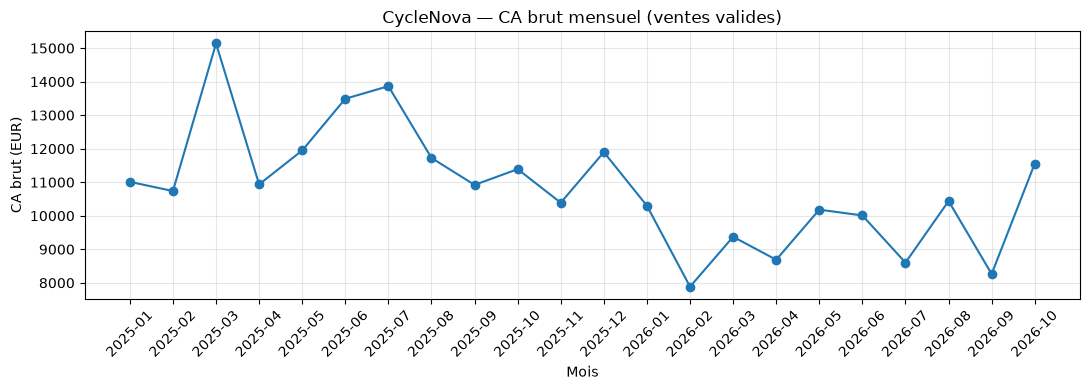

In [27]:
ca_mensuel = sql("""
SELECT mois,
       ROUND(SUM(montant), 2) AS ca_eur,
       COUNT(*)               AS n_ventes
FROM ventes_valides
GROUP BY mois
ORDER BY mois
""")
display(ca_mensuel)

import matplotlib.pyplot as plt
plt.figure(figsize=(11, 4))
plt.plot(ca_mensuel["mois"], ca_mensuel["ca_eur"], marker="o")
plt.title("CycleNova — CA brut mensuel (ventes valides)")
plt.xlabel("Mois"); plt.ylabel("CA brut (EUR)")
plt.xticks(rotation=45); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

Contrôles et limites : mois est extrait de la date ISO (AAAA-MM), ce qui garantit un tri chronologique correct. Les données couvrent janvier 2025 → octobre 2026 : vérifier que le dernier mois est complet avant de le comparer aux autres.

In [28]:
display(sql("""
WITH
-- 1) Suppression des relevés en double
releves_uniques AS (
  SELECT DISTINCT id_produit, concurrent, date_releve, prix_concurrent
  FROM prix_concurrents
),
-- 2) Rang 1 = relevé le plus récent pour chaque (produit, concurrent)
releves_classes AS (
  SELECT *,
         ROW_NUMBER() OVER (PARTITION BY id_produit, concurrent ORDER BY date_releve DESC) AS rang
  FROM releves_uniques
),
-- 3) Catalogue dédoublonné
catalogue AS (
  SELECT DISTINCT id_produit, prix_catalogue FROM produits
)
SELECT
  r.concurrent,
  MAX(r.date_releve)                     AS date_dernier_releve,
  COUNT(*)                               AS n_produits_compares,
  ROUND(AVG(c.prix_catalogue), 2)        AS prix_catalogue_moyen,
  ROUND(AVG(r.prix_concurrent), 2)       AS prix_concurrent_moyen,
  ROUND(AVG(100.0 * (c.prix_catalogue - r.prix_concurrent) / r.prix_concurrent), 1) AS ecart_moyen_pct,
  SUM(c.prix_catalogue > r.prix_concurrent) AS n_cyclenova_plus_cher,
  SUM(c.prix_catalogue < r.prix_concurrent) AS n_cyclenova_moins_cher
FROM releves_classes r
JOIN catalogue c ON r.id_produit = c.id_produit
WHERE r.rang = 1
  AND c.prix_catalogue IS NOT NULL
GROUP BY r.concurrent
"""))

,concurrent,date_dernier_releve,n_produits_compares,prix_catalogue_moyen,prix_concurrent_moyen,ecart_moyen_pct,n_cyclenova_plus_cher,n_cyclenova_moins_cher
0,Concurrent A,2026-10-01,63,60.57,61.48,0.3,31,32
1,Concurrent B,2026-10-01,63,60.57,60.66,2.3,34,29


Contrôles et limites : un seul relevé par (produit, concurrent), le plus récent, après suppression des 2 relevés dupliqués. On évite ainsi la multiplication des lignes vue à l’étape 1. Le produit sans prix_catalogue est exclu de la comparaison (63 produits comparés). Un écart positif signifie que CycleNova est plus cher que le concurrent. Limites : comparaison du prix catalogue, et non du prix réellement payé (prix_unitaire après remise) ; le dernier relevé date du 1er octobre 2026, il peut ne plus refléter les prix actuels.

## Étape 6 — Synthèse (à rédiger)

Présentez au moins trois observations chiffrées et deux limites de qualité ; distinguez ce qui est mesuré de ce qui est supposé.

### Synthèse

**Observations chiffrées (mesurées sur `ventes_valides`, 2 950 lignes)**

1. **Volume global** : le chiffre d'affaires brut (après remise, hors remboursement) s'élève à **238 742 €** sur **2 950 ventes valides** (janvier 2025 → octobre 2026). Le **taux de retour est de 16,8 %** (494 retours sur 2 941 lignes à étiquette connue).
2. **Concentration du CA** : les **Chaussures** génèrent **27,3 % du CA** (65 201 €) avec seulement 374 ventes, contre 4,2 % pour les Bidons (352 ventes). Le panier moyen par ligne va de ~174 € (Chaussures) à ~29 € (Bidons) : le CA est porté par le prix unitaire plus que par le volume.
3. **Retours par canal** : l'**Application (19,4 %)** et la **Marketplace (18,3 %)** ont un taux de retour supérieur au **Site web (15,6 %)**, qui concentre pourtant 61 % des ventes valides.
4. **Tendance** : sur les mêmes mois (janvier–octobre), le CA passe de **121 161 € en 2025 à 95 295 € en 2026 (−21 %)**, avec un nombre de ventes en baisse comparable (1 486 → 1 182, −20 %). La baisse vient donc surtout du **volume** plutôt que du prix moyen.
5. **Positionnement prix** : au dernier relevé (1er octobre 2026), le prix catalogue CycleNova est en moyenne **0,3 % au-dessus du Concurrent A** et **2,3 % au-dessus du Concurrent B**. CycleNova est plus cher sur environ la moitié des 63 produits comparés (31 face à A, 34 face à B).

**Limites de qualité**

- **Lignes exclues** : 5 doublons supprimés et 50 lignes exclues (clé produit manquante ou inconnue, quantité, prix ou remise invalides), soit ~1,7 % des ventes. Leur CA n'est ni estimé ni corrigé : les totaux sont donc des **minima** sur les données fiables.
- **Étiquettes de retour** : 9 lignes (retour manquant ou égal à 2) sont exclues du taux de retour. Le groupe « canal inconnu » (8 ventes) est trop petit pour être interprété.
- **Prix concurrents** : relevés **mensuels** et sur **deux concurrents** seulement. Ils comparent le **prix catalogue**, pas le prix réellement payé après remise ; un produit sans prix catalogue est exclu de la comparaison.

**Mesuré vs supposé**

- *Mesuré* : les montants, effectifs, taux et écarts de prix ci-dessus, calculés directement sur les données nettoyées selon les règles de l'étape 4.
- *Supposé / non démontré* : les causes. Rien ne prouve que la baisse 2026 est liée aux prix des concurrents, ni que le canal *cause* les retours : un canal peut vendre davantage de produits à risque (tailles de chaussures ou de textile, par exemple). Les écarts entre canaux n'ont pas été testés statistiquement. Ces hypothèses seraient à vérifier : taux de retour par canal **et** catégorie, test de significativité, analyse de l'élasticité prix.